# 01 – Xem dataset (bước đầu tiên)
Chạy từng cell từ trên xuống. Đổi biến `DATASET` để xem dataset còn lại. Mỗi dataset được đọc **riêng biệt**.

Dữ liệu đặt trong `data/unsw_nb15/` và `data/cicids2017/`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from src import config, data

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)

DATASET = "unsw_nb15"   # đổi thành "cicids2017" để chạy dataset kia


## 1. Đọc dữ liệu

In [2]:
train, test = data.load(DATASET)
print("train:", train.shape, "| test:", None if test is None else test.shape)
LABEL = data.find_label_col(train, DATASET)
print("Cột nhãn:", LABEL)

train: (175341, 54) | test: (82332, 54)
Cột nhãn: attack_cat


## 2. Bảng dữ liệu (30 dòng đầu)

In [3]:
train.head(30)

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label,log_dur,log_sbytes,log_dbytes,log_sload,log_dload,log_rate,log_sjit,log_djit,log_sinpkt,log_dinpkt
0,0.121478,tcp,unspecified,FIN,6,4,258,172,74.087490,252,254,1.415894e+04,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0,0.114647,5.556828,5.153292,9.558172,9.047394,4.318654,3.439698,2.551833,3.230630,2.238047
1,0.649902,tcp,unspecified,FIN,14,38,734,42014,78.473372,62,252,8.395112e+03,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0,0.500716,6.599870,10.645782,9.035524,13.129483,4.375422,4.133997,7.236180,3.930158,2.799283
2,1.623129,tcp,unspecified,FIN,8,16,364,13186,14.170161,62,252,1.572272e+03,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0,0.964368,5.899897,9.486987,7.360913,11.017485,2.719330,9.751535,9.343290,5.450504,4.641861
3,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,252,2.740179e+03,3358.622070,1,3,152.876547,90.235726,259.080172,4991.784669,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0,0.986429,6.444131,6.647688,7.916143,8.119584,2.686289,5.560990,8.515749,5.036151,4.513447
4,0.449454,tcp,unspecified,FIN,10,6,534,268,33.373826,254,252,8.561499e+03,3987.059814,2,1,47.750333,75.659602,2415.837634,115.807000,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0,0.371187,6.282267,5.594711,9.055147,8.291060,3.537295,7.790215,4.760523,3.886712,4.339375
5,0.380537,tcp,unspecified,FIN,10,6,534,268,39.417980,254,252,1.011203e+04,4709.134766,2,1,39.928778,52.241000,2223.730342,82.550500,255,3984155503,1796040391,255,0.172934,0.119331,0.053603,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0,0.322473,6.282267,5.594711,9.221580,8.457472,3.699275,7.707391,4.425451,3.711833,3.974829
6,0.637109,tcp,unspecified,FIN,10,8,534,354,26.683033,254,252,6.039783e+03,3892.583740,2,1,68.267778,81.137711,4286.828570,119.422719,255,1787309226,1767180493,255,0.143337,0.069136,0.074201,53,44,0,0,43,1,1,1,1,40,0,0,0,1,39,0,Normal,0,0.492932,6.282267,5.872118,8.706289,8.267085,3.320820,8.363536,4.791008,4.237980,4.408397
7,0.521584,tcp,unspecified,FIN,10,8,534,354,32.593026,254,252,7.377527e+03,4754.747070,2,1,55.794000,66.054141,3770.580726,118.962633,255,205985702,316006300,255,0.116615,0.059195,0.057420,53,44,0,0,43,1,3,3,1,40,0,0,0,3,39,0,Normal,0,0.419752,6.282267,5.872118,8.906329,8.467109,3.514318,8.235249,4.787180,4.039431,4.205500
8,0.542905,tcp,unspecified,FIN,10,8,534,354,31.313031,254,252,7.087796e+03,4568.018555,2,1,60.210889,68.109000,4060.625597,106.611547,255,884094874,3410317203,255,0.118584,0.066133,0.052451,53,44,0,0,43,1,3,3,1,40,0,0,0,3,39,0,Normal,0,0.433667,6.282267,5.872118,8.866271,8.427054,3.475471,8.309339,4.678528,4.114325,4.235685
9,0.258687,tcp,unspecified,FIN,10,6,534,268,57.985135,254,252,1.487512e+04,6927.291016,2,1,27.505111,39.106801,1413.686415,57.200395,255,3368447996,584859215,255,0.087934,0.063116,0.024818,53,45,0,0,43,1,3,3,1,40,0,0,0,3,39,0,Normal,0,0.230069,6.282267,5.594711,9.607513,8.843368,4.077285,7.254663,4.063892,3.350083,3.691546


## 3. Kiểu dữ liệu, giá trị thiếu, số giá trị khác nhau

In [4]:
pd.DataFrame({"dtype": train.dtypes.astype(str), "missing": train.isna().sum(), "unique": train.nunique()})

,dtype,missing,unique
dur,float64,0,74039
proto,object,0,133
service,object,0,13
state,object,0,9
spkts,int64,0,480
dpkts,int64,0,443
sbytes,int64,0,7214
dbytes,int64,0,6660
rate,float64,0,76991
sttl,int64,0,11


## 4. Số bản ghi theo lớp tấn công

,attack_cat,rows,percent,rare
0,Normal,56000,31.938,False
1,Generic,40000,22.813,False
2,Exploits,33393,19.045,False
3,Fuzzers,18184,10.371,False
4,DoS,12264,6.994,False
5,Reconnaissance,10491,5.983,False
6,Analysis,2000,1.141,False
7,Backdoor,1746,0.996,False
8,Shellcode,1133,0.646,False
9,Worms,130,0.074,True


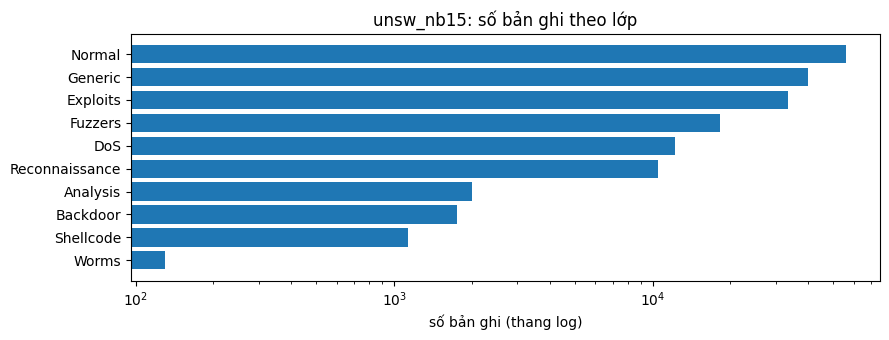

In [5]:
vc = data.class_counts(train, LABEL)
display(vc)
fig, ax = plt.subplots(figsize=(9, max(3, 0.35*len(vc))))
ax.barh(vc[LABEL].astype(str)[::-1], vc["rows"][::-1])
ax.set_xscale("log"); ax.set_xlabel("số bản ghi (thang log)"); ax.set_title(f"{DATASET}: số bản ghi theo lớp")
plt.tight_layout(); plt.show()

## 5. Các lớp hiếm
Lớp có ít hơn `RARE_THRESHOLD` bản ghi (mặc định 1000, chỉnh trong `src/config.py`). Đây là lớp SynthGuard nhắm tới, nhưng cũng là lớp khó cho CTGAN học.

In [6]:
vc[vc['rare']]

,attack_cat,rows,percent,rare
9,Worms,130,0.074,True


## 6. Xem toàn bộ bảng
Cài extension **Data Wrangler** của VS Code, rồi mở biến `train` trong tab *Variables* để lướt và lọc cả bảng. Hoặc lọc một lớp:
```python
train[train[LABEL] == "Worms"]
```